# 102.6. Finding DP2 transients in ELAIS-S1
Notebook adapted from "Catalog Access with LSDB notebook", originally developed by the Rubin community science team.

<div style="max-width:300px; float: left; margin-right: 1em">

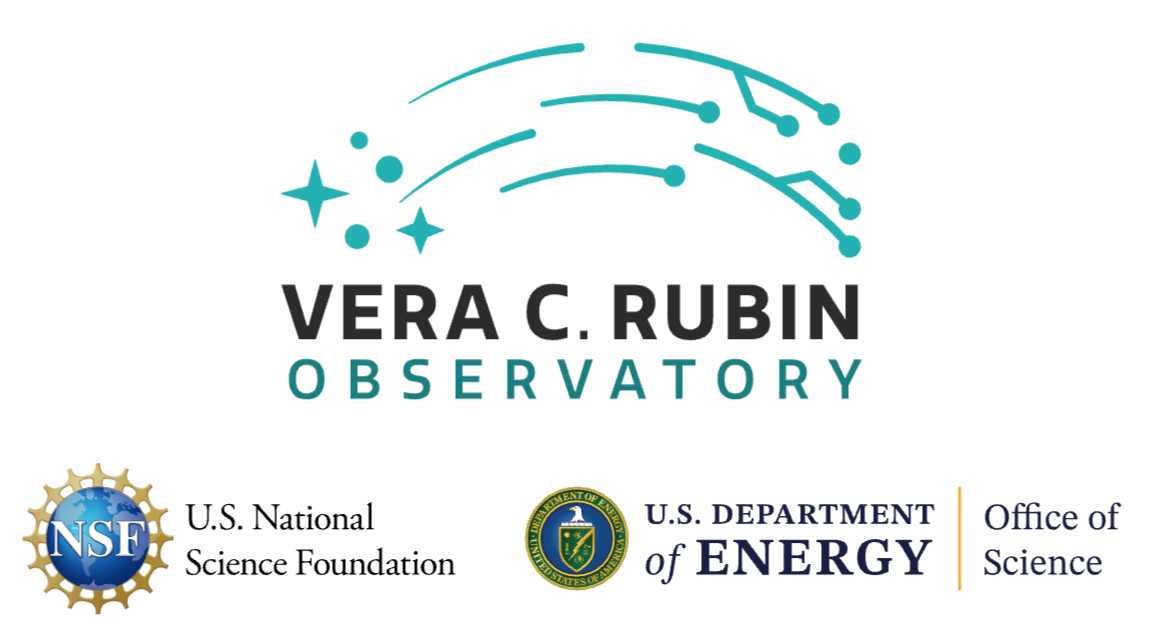

</div>

For the Rubin Science Platform at data.lsst.cloud. \
Data Release: <a href="https://dp2.lsst.io/">Data Preview 2</a> \
Container Size: Large \
LSST Science Pipelines version: v30.0.10 \
Last verified to run: 2026-07-27 \
Repository: [github.com/lsst/tutorial-notebooks](https://github.com/lsst/tutorial-notebooks)

**Science objective:** Search for an optical counterpart to the sub-solar-mass gravitational-wave candidate S251112cm among DP2 transients in the ELAIS-S1 deep drilling field, and learn how catalog crossmatches are used to vet candidates.

**Learning objective:** How to access Rubin data in LSDB format.

**LSST data products:** `Object`, `DiaObject`, `DiaSource`, `ForcedSource`, and `ForcedSourceOnDiaObject`

**Packages:** `lsdb`

**Credit:**
Originally developed by the Rubin Community Science team with input from Neven Caplar, Tianqing Zhang, and Olivia Lynn.
Please consider acknowledging them if this notebook is used for the preparation of journal articles, software releases, or other notebooks.

## Science background

### Searching for electromagnetic counterparts to gravitational-wave events

When the LIGO-Virgo-KAGRA (LVK) network detects a compact binary merger, it issues a public alert within minutes containing the event time, a probability sky map, and (for most events) a luminosity-distance estimate. Mergers that involve at least one neutron star can eject neutron-rich material that powers a **kilonova**: a fast-evolving, red, relatively faint (peak absolute magnitude around -15 to -16) optical/infrared transient. The only secure example so far is AT 2017gfo, the counterpart to the binary neutron star merger GW170817 in the galaxy NGC 4993 at about 40 Mpc. Finding a counterpart pins down the host galaxy and redshift, enables standard-siren cosmology, and probes the physics of r-process nucleosynthesis and dense matter.

The fundamental difficulty is that GW localizations typically span **hundreds to thousands of square degrees**, and a deep survey of that area turns up thousands of unrelated transients and variables. An EM-GW search is therefore really a *vetting funnel*: you start with every difference-image detection and progressively remove things that cannot be the counterpart. A typical funnel looks like:

1. **Data quality**: remove artifacts, bad subtractions, dipoles, saturated or streaked detections, and low real/bogus scores.
2. **Solar System objects**: remove known asteroids (moving objects).
3. **Temporal coincidence**: keep sources that are *new* after the merger time and have no history of variability before it.
4. **Contextual vetting (catalog crossmatches)**: remove stars, AGN, and known quasars using archival catalogs.
5. **Spatial coincidence**: keep sources inside the GW credible region (2D), and ideally in host galaxies at a distance consistent with the GW distance (3D).
6. **Light-curve evolution**: kilonovae fade much faster (roughly 0.3 to 1 mag/day in the optical) than most supernovae, so photometric evolution is a powerful discriminator.
7. **Follow-up**: spectroscopy and multi-wavelength observations of the few surviving candidates.

Rubin is a uniquely powerful facility for this work: its 9.6 deg$^2$ field of view and single-visit depth of roughly 24.5 mag can reach kilonovae out to several hundred Mpc. Its deep drilling fields (DDFs), such as ELAIS-S1, are observed at high cadence with deep templates, which makes them ideal places to look for fast transients if a GW localization happens to overlap them.

### S251112cm: a sub-solar-mass merger candidate

S251112cm was identified by the LVK collaboration in real-time data from LIGO Hanford, LIGO Livingston, and Virgo at **2025-11-12 15:18:45.362 UTC (GPS 1446995943.362)** ([GCN 42650](https://gcn.nasa.gov/circulars/42650)). Unusually, it was found by the MBTA pipeline's dedicated *sub-solar-mass* (SSM) search, whose template bank includes components lighter than the Sun. The online false alarm rate was initially estimated at about one per 6 years and later updated to about one per 4 years ([GCN 42690](https://gcn.nasa.gov/circulars/42690)). Because of the SSM template bank, the usual BNS/NSBH/BBH classification probabilities were not computed for this event.

| Quantity | Initial (BAYESTAR) | Updated (Bilby) |
|---|---|---|
| 90% credible area | 1220 deg$^2$ | 1681 deg$^2$ |
| Luminosity distance | 96 $\pm$ 29 Mpc | 93 $\pm$ 27 Mpc |

The event and its sky maps are on GraceDB: [gracedb.ligo.org/superevents/S251112cm](https://gracedb.ligo.org/superevents/S251112cm). In this notebook we use the updated Bilby sky map.

**Why is a sub-solar-mass merger interesting?** Standard stellar evolution is not expected to produce neutron stars or black holes below about one solar mass. A confirmed sub-solar-mass compact object would therefore point to new physics or new formation channels, such as primordial black holes (a dark matter candidate) or very light neutron stars formed by fragmentation inside collapsing massive stars. The expected EM counterpart is correspondingly uncertain: there may be none (e.g., for primordial black holes), a kilonova-like transient, or an associated stripped-envelope supernova. Some teams therefore deliberately kept young supernovae in their candidate lists rather than rejecting them.

**The follow-up campaign.** S251112cm triggered a large international search, including ZTF, ATLAS, BlackGEM/MeerLICHT, DECam, WFST, KMTNet, J-GEM, GRANDMA, Einstein Probe, Fermi-GBM, and the first Rubin Target-of-Opportunity observations since Rubin entered operations. Spectroscopic follow-up classified many of the reported candidates as Type Ia supernovae at redshifts too large to be associated with the GW event. You can browse the full set of reports on the [GCN event page for S251112cm](https://gcn.nasa.gov/circulars/events/ligovirgokagra-s251112cm); check there for the latest status.

**In this notebook** we perform our own version of this search in the DP2 data for the ELAIS-S1 deep drilling field, following the funnel described above.

<div class="alert alert-block alert-warning">
<b>Questions to think about before you start</b>

1. The GW distance is 93 $\pm$ 27 Mpc. Roughly what redshift range does this correspond to? Why do we care about this when vetting candidates?
2. AT 2017gfo peaked at an absolute magnitude of about $M \approx -16$. How bright would a similar kilonova appear at the distance of S251112cm? Could Rubin detect it? Could a 0.5 m telescope with a limiting magnitude of 19.5?
3. Why might a search confined to a single deep drilling field (a few deg$^2$) still be worthwhile, given a localization of more than 1000 deg$^2$?

Use the cell below to answer the first two questions quantitatively. *Hint:* `astropy.cosmology.z_at_value` and `Planck18.distmod` are useful.
</div>

In [ ]:
# EXERCISE: convert the GW distance range into a redshift range, and estimate
# the apparent magnitude of an AT2017gfo-like kilonova at that distance.
from astropy.cosmology import Planck18, z_at_value
import astropy.units as u

d_mean = 93 * u.Mpc
d_std = 27 * u.Mpc

# YOUR CODE HERE

## 1. Introduction

[LSDB](https://docs.lsdb.io/) is an open-source Python framework that enables fast all-sky cross-matching, bulk application of user-defined functions, and simplified analysis of time-domain (light curve) data. Built on top of [Dask](https://docs.dask.org/), LSDB uses the [HATS](https://hats.readthedocs.io/) (Hierarchical Adaptive Tiling Scheme) data format ([HEALPix](https://healpix.sourceforge.io/documentation.php)-sharded [Parquet](https://parquet.apache.org/docs/)), 
which provides an efficient, spatially-indexed format for storing catalog data.

LSDB also hosts many other datasets stored in the HATS format beyond the DP2 catalogs shown in this tutorial, but **the DP2 HATS catalogs are only available on the Rubin Science Platform (RSP).**
Find the full list of LSDB-hosted datasets at [data.lsdb.io](https://data.lsdb.io/).

> **Note:** This notebook is intended only as a simple tutorial on LSDB DP2 catalogs.
For more detailed examples and advanced use cases, see the full set of LSDB tutorials at [LSDB tutorials](https://docs.lsdb.io/en/latest/tutorials.html).

**References:**

- Descriptions of LSDB-formatted Rubin data: [https://data.lsdb.io/](https://data.lsdb.io/)
- LSDB documentation: [docs.lsdb.io](https://docs.lsdb.io/en/latest/index.html)
- [Working with Rubin Data using LSDB](https://docs.lsdb.io/en/latest/tutorial_toc/toc_rubin.html)
- [LSDB hackathon at the Rubin Community Workshop 2025](https://github.com/lincc-frameworks/RCW_Hackathon_2025_LSDB/tree/main)

**Related tutorials:** The 200-level tutorials on the `Object`, `DiaObject`, `DiaSource`, `ForcedSource`, and `ForcedSourceOnDiaObject` catalogs. The 300-level tutorial on how to access photometric redshifts in LSDB-formatted files. 

### 1.1. Import packages

Import the [LSDB package](https://github.com/astronomy-commons/lsdb/) to work with LSDB-formatted files, [`upath`](https://github.com/fsspec/universal_pathlib) for handling local and remote file paths uniformly, and `matplotlib.pyplot` for visualization.

In [1]:
import lsdb
import astropy.units as u
from astropy.coordinates import SkyCoord
from upath import UPath
import matplotlib.pyplot as plt
import numpy as np
from astropy.time import Time
from astropy.table import Table
from astroquery.xmatch import XMatch
import healpy as hp
import pandas as pd
from lsst.utils.plotting import (get_multiband_plot_colors,
                                 get_multiband_plot_symbols)

# NEED to install the packages below into the RSP conda environment:
from ligo.skymap.io import read_sky_map
from ligo.skymap.postprocess import find_greedy_credible_levels

/home/sanand/.local/lib/python3.13/site-packages/ligo/skymap/io/events/ligolw.py:26: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


In [2]:
import os
import site

# Disable the flag that forces Conda to ignore user-site packages
os.environ["PYTHONNOUSERSITE"] = "0"

# Reload the site-packages configuration to append ~/.local paths
site.main()

In [3]:
lsdb.show_versions()


--------      SYSTEM INFO      --------
python        : 3.13.9
python-bits   : 64
OS            : Linux
OS-release    : 6.12.94+
Version       : #1 SMP Tue Aug  4 08:42:20 UTC 2026
machine       : x86_64
processor     : 
byteorder     : little
LC_ALL        : 
LANG          : 
--------   INSTALLED VERSIONS   --------
lsdb          : 0.10.4
hats          : 0.10.4
nested-pandas : 0.6.10
pandas        : 2.3.3
numpy         : 2.3.5
dask          : 2026.7.1
pyarrow       : 21.0.0
fsspec        : 2026.6.0


In [4]:
# Dask puts out more advisory logging than we care for in this tutorial.
# It takes some doing to quiet all of it, but this recipe works.

import dask
import os

dask.config.set({"logging.distributed": "critical"})

import logging

# This also has to be done, for the above to be effective
logger = logging.getLogger("distributed")
logger.setLevel(logging.CRITICAL)

import warnings

# Finally, suppress the specific warning about Dask dashboard port usage
warnings.filterwarnings("ignore", message="Port 8787 is already in use.")

In [5]:
from dask.distributed import Client

client = Client(
    n_workers=4,
    threads_per_worker=1,
    memory_limit="auto",
    local_directory=f"/deleted-sundays/{os.environ.get('USER', 'dask_scratch')}",
)
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: https://sanand.nb.data.lsst.cloud/nb/user/sanand/proxy/8787/status,
Dashboard: https://sanand.nb.data.lsst.cloud/nb/user/sanand/proxy/8787/status,Workers: 4
Total threads: 4,Total memory: 32.00 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:43459,Workers: 0
Dashboard: https://sanand.nb.data.lsst.cloud/nb/user/sanand/proxy/8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:33509,Total threads: 1
Dashboard: https://sanand.nb.data.lsst.cloud/nb/user/sanand/proxy/36339/status,Memory: 8.00 GiB
Nanny: tcp://127.0.0.1:43621,


Define the filter names, colors, and symbols to use when plotting.

In [6]:
filter_colors = get_multiband_plot_colors()
filter_names = filter_colors.keys()
filter_symbols = get_multiband_plot_symbols()

Set the base path to the LSDB-formatted DP2 data on the RSP.

In [7]:
base_path = UPath("/rubin/lsdb_data/dp2")

Set the directory where this notebook will save intermediate data products (the filtered catalog, the GW sky map, candidate tables, and light-curve figures).

> **Edit the path below** to point to a directory in your RSP home area where you have write access, e.g. `/home/<your_username>/DATA/`. If you leave the placeholder unchanged, the notebook falls back to `~/DATA/`.

In [8]:
# EDIT THIS: a directory where you have write access
base_data_path = "/home/sanand/DATA/"

if "sanand" in base_data_path:
    base_data_path = os.path.join(os.path.expanduser("~"), "DATA", "")
    print(f"base_data_path still contains the placeholder; using {base_data_path} instead")

os.makedirs(base_data_path, exist_ok=True)

base_data_path still contains the placeholder; using /home/sanand/DATA/ instead


## 2. Access the LSDB DP2 catalogs

The LSDB DP2 read-only catalogs available on the Rubin Science Platform at `data.lsst.cloud` are located in the directory `/rubin/lsdb_data`.

Two of them are HATS **collections** (a main catalog packaged together with a margin cache and ID-based index tables):

- `object_collection`: the `Object` table, with the forced photometry nested in an `objectForcedSource` column
- `dia_object_collection`: the `DiaObject` table, with `diaSource` and `diaObjectForcedSource` nested columns

The third is a **standalone catalog**:

- `object_photoz`: the photometric redshift estimates table (see Section 2.3, below)

Note that, unlike DP1 in the Rubin Science Platform, there is no `object_collection_lite` catalog for DP2. 

### 2.2. dia_object_collection

This LSDB-formatted catalog is the same as the DP2 `DiaObject` table, with the `DiaSource` and `ForcedSourceOnDiaObject` records nested per object.

[Column descriptions for the DP2 DiaObject table](https://sdm-schemas.lsst.io/dp2.html#DiaObject).

As with the DP2 `object_collection`, a subset of columns is lazily loaded by default: `dec`, `diaObjectId`, `nDiaSources`, `ra`, and `tract`, plus the nested light-curve columns `diaSource` and `diaObjectForcedSource` (each with a subset of their subcolumns).
To load a different set of columns, pass the `columns` argument to `open_catalog`.

In [9]:
dia_object_cat = lsdb.open_catalog(base_path / "dia_object_collection", columns=['diaObjectId', 'ra', 'dec', 'nDiaSources', 'tract', 'diaSource', 'diaObjectForcedSource'])
# pass additional columns in the dia_object_cat (including the psfFluxNdata of each column)

#### 2.2.1. Access nested light curves

Check which columns are nested.

In [10]:
dia_object_cat.nested_columns

['diaSource', 'diaObjectForcedSource']

The subcolumns in these nested columns are mostly the same as the DP2 `DiaSource` and `ForcedSourceOnDiaObject` tables.

[Column descriptions for the DP2 DiaSource table](https://sdm-schemas.lsst.io/dp2.html#DiaSource).

[Column descriptions for the DP2 ForcedSourceOnDiaObject table](https://sdm-schemas.lsst.io/dp2.html#ForcedSourceOnDiaObject).

There are four additional subcolumns:
* `psfMag` and `psfMagErr` (in both nested columns)
* `scienceMag` and `scienceMagErr` (in the `diaSource` nested column only)

> **Warning:** For both nested columns, the `psfMag` column has been calculated from the `psfFlux` column, but they are not the same: in the `DiaSource` table `psfFlux` is the PSF fit flux in the difference image, but in the `ForcedSourceOnDiaObject` table `psfFlux` is the PSF forced photometry flux in the direct (or science) image. Fluxes measured on a difference image will be negative when the object is brighter in the template image than in the direct (science) image, and so typically, difference-image fluxes are not converted to magnitudes.

Option to display the subcolumns in the nested columns.

Our goal: find all possible extragalactic transients in the ELAIS-S1 deep drilling field with spatial and temporal overlap with S251112cm.

In [11]:
# coordinates of ELAIS_S1
# radius for this region is 1.0 deg, add 1.75 deg to the region to account for the Rubin field of view
ra_elaiss = 9.5
dec_elaiss = -44.0

## 3. Retrieve the GW sky map from GraceDB

LVK sky maps are distributed through [GraceDB](https://gracedb.ligo.org/), the gravitational-wave candidate event database. Each superevent has a public file list that can be queried with a simple REST API call. Sky maps are HEALPix FITS files that store, for every pixel on the sky, the posterior probability that the source lies in that pixel (plus, for 3D maps, the parameters of the distance distribution along that line of sight).

Two flavours exist: **multi-order** files (`*.multiorder.fits`), which use adaptive resolution and are the current LVK standard, and older flattened single-resolution files (`*.fits.gz`). `ligo.skymap.io.read_sky_map` reads either and, by default, returns a flattened RING-ordered HEALPix map, which is what `healpy` expects.

The cell below lists the sky maps available for S251112cm and downloads the updated Bilby map announced in GCN 42690. Files on GraceDB can have several versions (`name,0`, `name,1`, ...); requesting the bare name returns the latest version.

In [12]:
import requests
from pathlib import Path

superevent_id = "S251112cm"
gracedb_files_url = f"https://gracedb.ligo.org/api/superevents/{superevent_id}/files/"

# List all files attached to the superevent (a dictionary of {filename: download URL})
response = requests.get(gracedb_files_url, timeout=60)
response.raise_for_status()
available_files = response.json()

skymap_files = sorted(f for f in available_files if ".fits" in f and "," not in f)
print("Sky maps available on GraceDB for", superevent_id)
for f in skymap_files:
    print("  ", f)

# Download the updated Bilby sky map (GCN 42690). Change this to compare with the BAYESTAR map.
skymap_name = "Bilby.fits.gz,1"
skymap_path = Path(base_data_path) / f"{superevent_id}_{skymap_name}"

if not skymap_path.exists():
    r = requests.get(gracedb_files_url + skymap_name, timeout=300)
    r.raise_for_status()
    skymap_path.write_bytes(r.content)
    print(f"Downloaded {skymap_name} -> {skymap_path}")
else:
    print(f"Using cached sky map at {skymap_path}")

Sky maps available on GraceDB for S251112cm
   Bilby.fits.gz
   Bilby.multiorder.fits
   bayestar.fits.gz
   bayestar.multiorder.fits
Downloaded Bilby.fits.gz,1 -> /home/sanand/DATA/S251112cm_Bilby.fits.gz,1


Read the sky map, then compute some summary quantities: the area of the 50% and 90% credible regions, the distance estimate stored in the FITS header, and the probability that falls within our ELAIS-S1 search region.

The *credible level* of a pixel is computed with the "greedy" algorithm: sort pixels from most to least probable and accumulate their probability. A pixel's credible level is the cumulative probability at which it is reached, so the 90% credible region is the set of pixels with credible level $\leq 0.9$.

In [13]:
gw_prob, gw_meta = read_sky_map(str(skymap_path))
gw_nside = hp.npix2nside(len(gw_prob))
gw_credible_levels = find_greedy_credible_levels(gw_prob)
pix_area_deg2 = hp.nside2pixarea(gw_nside, degrees=True)

print(f"HEALPix nside = {gw_nside}")
for level in [0.5, 0.9]:
    area = np.sum(gw_credible_levels <= level) * pix_area_deg2
    print(f"{int(level*100)}% credible area: {area:.0f} deg^2")
if "distmean" in gw_meta:
    print(f"Distance: {gw_meta['distmean']:.0f} +/- {gw_meta['diststd']:.0f} Mpc")

# Probability enclosed within the ELAIS-S1 search region used for the cone search below
search_radius_deg = 2.75
elaiss_vec = hp.ang2vec(ra_elaiss, dec_elaiss, lonlat=True)
elaiss_pix = hp.query_disc(gw_nside, elaiss_vec, np.radians(search_radius_deg))
elaiss_center_pix = hp.ang2pix(gw_nside, ra_elaiss, dec_elaiss, lonlat=True)

print(f"GW probability inside the {search_radius_deg} deg ELAIS-S1 region: {gw_prob[elaiss_pix].sum():.4f}")
print(f"Credible level at the ELAIS-S1 center: {gw_credible_levels[elaiss_center_pix]:.3f}")

HEALPix nside = 512
50% credible area: 371 deg^2
90% credible area: 1681 deg^2
Distance: 93 +/- 27 Mpc
GW probability inside the 2.75 deg ELAIS-S1 region: 0.0104
Credible level at the ELAIS-S1 center: 0.931


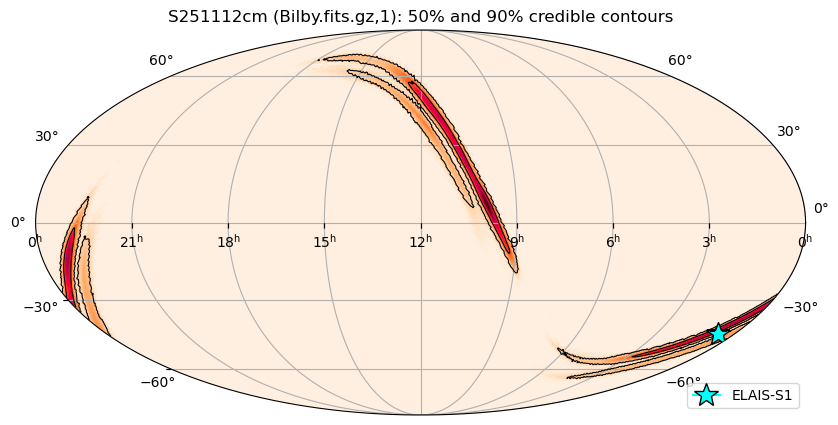

In [14]:
# Plot the sky map with the 50% and 90% contours and mark ELAIS-S1
import ligo.skymap.plot  # registers the 'astro ... mollweide' projections

fig = plt.figure(figsize=(10, 5))
ax = plt.axes(projection="astro hours mollweide")
ax.grid()
ax.imshow_hpx((gw_prob, "ICRS"), nested=False, cmap="cylon")
ax.contour_hpx((gw_credible_levels * 100, "ICRS"), nested=False,
               levels=[50, 90], colors="k", linewidths=0.8)
ax.plot(ra_elaiss, dec_elaiss, marker="*", ms=18, color="cyan", mec="k",
        transform=ax.get_transform("world"), label="ELAIS-S1")
ax.legend(loc="lower right")
ax.set_title(f"{superevent_id} ({skymap_name}): 50% and 90% credible contours")
plt.show()

<div class="alert alert-block alert-warning">
<b>Questions: the GW localization</b>

1. What fraction of the total GW probability lies inside the ELAIS-S1 search region? Compare that to the fraction of the 90% credible *area* it covers. What does this tell you about the chance that the counterpart (if any) is in our field?
2. Repeat the download with the initial `bayestar.fits.gz,1` map. How do the localization area and the probability enclosed by ELAIS-S1 change between the two maps? Why do LVK sky maps change after the initial alert?
3. The sky map is three-dimensional. Use `read_sky_map(str(skymap_path), distances=True)` to obtain the per-pixel distance distribution, and find the most likely distance along the line of sight toward ELAIS-S1. Is it consistent with the all-sky value?
</div>

In [ ]:
# YOUR CODE HERE (optional exercise)

In [15]:
dia_object_cat_elaiss = dia_object_cat.cone_search(ra=ra_elaiss, dec=dec_elaiss,
                                          radius_arcsec=2.75 * 3600.0)

In [11]:
dia_object_cat_elaiss

,diaObjectId,ra,dec,nDiaSources,tract,diaSource,diaObjectForcedSource
npartitions=149,,,,,,,
"Order: 4, Pixel: 2209",int64[pyarrow],double[pyarrow],double[pyarrow],int64[pyarrow],int64[pyarrow],"nested<visit: [int64], detector: [int16], ssOb...","nested<parentObjectId: [int64], coord_ra: [dou..."
...,...,...,...,...,...,...,...
"Order: 5, Pixel: 8871",...,...,...,...,...,...,...
"Order: 4, Pixel: 2220",...,...,...,...,...,...,...


In [10]:
dia_object_cat_elaiss.head(3)

Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

diaObjectId        ra        dec  nDiaSources  \
_healpix_29                                                                 
2487954529375141916  737999832425168907  9.331861 -46.742659            6   
2487954543020794070  737999832425169175  9.309507 -46.744907            1   
2487954553363809676  737999832425169162  9.321177 -46.742438            1   

                     tract  u_psfFluxNdata  g_psfFluxNdata  r_psfFluxNdata  \
_healpix_29                                                                  
2487954529375141916   2535               0               5               0   
2487954543020794070   2535               0               0               0   
2487954553363809676   2535               0               0               0   

                     i_psfFluxNdata  z_psfFluxNdata  \
_healpix_29                                           
2487954529375141916               1               0   
2487954543020794070               1               0   
2487954553363809676               1               0   

                                                             diaSource  \
_healpix_29                                                              
2487954529375141916  [{visit: 2025072300527, detector: 160, ssObjec...   
2487954543020794070  [{visit: 2025111400204, detector: 163, ssObjec...   
2487954553363809676  [{visit: 2025111400204, detector: 163, ssObjec...   

                                                 diaObjectForcedSource  
_healpix_29                                                             
2487954529375141916  [{parentObjectId: 0, coord_ra: 9.331861, coord...  
2487954543020794070  [{parentObjectId: 0, coord_ra: 9.309507, coord...  
2487954553363809676  [{parentObjectId: 0, coord_ra: 9.321177, coord...

Exercise: try writing your own query to select for diaObject that have "good" diaSources. Refer back to https://sdm-schemas.lsst.io/dp2.html to decide which criteria to filter on. Hint: use the syntax structure below:

In [ ]:
# EXERCISE: uncomment and complete the line below with your own selection criteria.
# Each .query() call applies one cut; chain as many as you need.
# Compare your result with the reference selection in the next cell.

# my_dia_object_cat_multidet = dia_object_cat_elaiss.query("YOUR CRITERIA HERE").query("YOUR SECOND CRITERIA HERE")

In [16]:
# Here are the selection criteria we actually use
dia_object_cat_multidet = dia_object_cat_elaiss.query("nDiaSources > 2").query("diaSource.reliability > 0.5").query("diaSource.ssObjectId == 0").query("diaSource.isDipole == 'False'").query("diaSource.extendedness < 1").query("diaSource.psfFlux_flag == 'False'").query("diaSource.psfFlux_flag_edge == 'False'").query("diaSource.forced_PsfFlux_flag == 'False'").query("diaSource.forced_PsfFlux_flag_edge == 'False'").query("diaSource.centroid_flag == 'False'").query("diaSource.shape_flag == 'False'").query("diaSource.pixelFlags_bad == 'False'").query("diaSource.pixelFlags_cr == 'False'").query("diaSource.pixelFlags_saturated == 'False'").query("diaSource.pixelFlags_streak == 'False'").query("diaSource.pixelFlags_nodata == 'False'").query("diaSource.glint_trail == 'False'")

<div class="alert alert-block alert-warning">
<b>Questions: data-quality cuts</b>

1. For each criterion in the query above, explain in a sentence what kind of contaminant it is designed to remove. (The [DiaSource schema](https://sdm-schemas.lsst.io/dp2.html#DiaSource) is a good reference.)
2. The cut `diaSource.extendedness < 1` keeps point-like difference-image detections. Why is that sensible for a transient search, even though the transient's host galaxy is extended?
3. The cut `diaSource.ssObjectId == 0` removes detections associated with known Solar System objects. Can you think of a kind of moving object that this would *not* catch?
4. Every cut removes some real transients along with the junk. Which of these cuts do you think is most likely to remove a genuine kilonova, and why?
</div>

In [17]:
dia_object_cat_filtered = dia_object_cat_multidet.map_partitions(
    lambda df: df.dropna(subset=["diaSource"])
)

In [12]:
dia_object_cat_filtered.head(3)

Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

diaObjectId         ra        dec  nDiaSources  \
_healpix_29                                                                  
2488076028917038145  738008147481854190  11.203252 -46.394992            3   
2488079968805673759  738008834676621323  11.403427 -46.295057            9   
2488090506766457255  738008697237667950  11.747967 -46.243007            6   

                     tract                                          diaSource  \
_healpix_29                                                                     
2488076028917038145   2536  [{visit: 2025102600232, detector: 124, ssObjec...   
2488079968805673759   2536  [{visit: 2025072300527, detector: 70, ssObject...   
2488090506766457255   2536  [{visit: 2025102600226, detector: 12, ssObject...   

                                                 diaObjectForcedSource  
_healpix_29                                                             
2488076028917038145  [{parentObjectId: 0, coord_ra: 11.203252, coor...  
2488079968805673759  [{parentObjectId: 0, coord_ra: 11.403427, coor...  
2488090506766457255  [{parentObjectId: 0, coord_ra: 11.747967, coor...

In [13]:
dia_object_cat_clean = dia_object_cat_filtered.prune_empty_partitions()

/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/lsdb/catalog/dataset/healpix_dataset.py:1281: RuntimeWarning: Pruning empty partitions is expensive. It may run slow!
  warnings.warn("Pruning empty partitions is expensive. It may run slow!", RuntimeWarning)


Computing Catalog:   0%|          | 0/149 [00:00<?, ?it/s]

In [ ]:
# Save the catalog! (overwrite=True lets you re-run this cell)
dia_object_cat_clean.write_catalog(base_data_path + "dp2_elaiss_filtered_catalog", overwrite=True)

In [18]:
# Reload the filtered catalog from disk. After a kernel restart, you can resume from here
# (after re-running the imports, the Dask client, and the cell that defines base_data_path).
dia_object_cat_clean = lsdb.open_catalog(base_data_path + "dp2_elaiss_filtered_catalog")

### Temporal coincidence

A counterpart to a neutron star merger typically must appear *after* the merger. The function below keeps objects whose first detection falls after `mjd_start` (four days before the merger, which also rejects anything with a long history of variability, such as AGN or variable stars) and that were detected at least once by `mjd_end` (four days after the merger), with at least three detections in total. The reason for expanding the time window prior to the merger, instead of requiring the first detection to be after the merger, is to allow for another kind of hypothesized subsolar mass merger counterpart, called as a "superkilonova" (see these papers for more information:  https://arxiv.org/abs/2508.17183; https://arxiv.org/abs/2510.23732) whose emission could be detectable a few days prior to merger. Instead, if we are just interested in classical kilonovae associated with neutron star mergers, we would require all detections to be after the merger time.

In [19]:
# compute the MJD time of the GW merger to set the time window for the search
gw_time = Time(1446995943.36, format='gps')
(gw_time + 4 * u.day).mjd

np.float64(60995.63845324074)

In [20]:
# here are the relevant timeframes. We are searching only for transients discovered within a short time window of the merger
mjd_start = 60987.63845324074
mjd_end = 60995.63845324074

def keep_object(mjd):
    n_sources = len(mjd)
    return {
        "keep_object": bool(
            np.any(mjd <= mjd_end) and np.all(mjd > mjd_start) and n_sources > 2
        )
    }
# create a helper column to implement temporal filtering
dia_obj_cat2 = dia_object_cat_clean.map_rows(
    keep_object,
    columns=["diaSource.midpointMjdTai"],
    row_container="args",
    meta={"keep_object": bool},
    append_columns=True,
)

# Filter and drop the helper column
dia_obj_cat_temporal = dia_obj_cat2.query("keep_object == True").drop(columns=["keep_object"])

In [30]:
# look at the table to make sure the query worked
dia_obj_cat_temporal.head(3)

Computing Catalog:   0%|          | 0/1 [00:00<?, ?it/s]

diaObjectId         ra        dec  nDiaSources  \
_healpix_29                                                                  
2488151309154490357  738008491079237904  10.192323 -46.458899            3   
2488212635072811383  739158580241891365  10.801117 -45.906233            9   
2488235237023367691  739168475846541323  11.806938 -45.270005           61   

                     tract                                          diaSource  \
_healpix_29                                                                     
2488151309154490357   2536  [{visit: 2025111400202, detector: 64, ssObject...   
2488212635072811383   2704  [{visit: 2025111400082, detector: 3, ssObjectI...   
2488235237023367691   2705  [{visit: 2025110800052, detector: 71, ssObject...   

                                                 diaObjectForcedSource  
_healpix_29                                                             
2488151309154490357  [{parentObjectId: 0, coord_ra: 10.192323, coor...  
2488212635072811383  [{parentObjectId: 0, coord_ra: 10.801117, coor...  
2488235237023367691  [{parentObjectId: 0, coord_ra: 11.806938, coor...

In [20]:
dia_obj_cat_temporal.estimate_size()

/opt/lsst/software/stack/conda/envs/lsst-scipipe-12.3.0-exact/lib/python3.13/site-packages/lsdb/catalog/dataset/healpix_dataset.py:1936: UserWarning: The estimates provided are approximations.
  warnings.warn("The estimates provided are approximations.")


You selected 7/8 columns.
You selected 148/148 pixels.
Expect up to 6,821 results (100.00% of the full catalog).
Expect up to 213.8 MiB in MEMORY.
Expect up to 181.1 MiB on DISK.


In [ ]:
# let's take a look at the columns in the diaSource tables
dia_obj_cat_temporal["diaSource"].columns

In [21]:
# let's check how many objects actually pass our criteria
n_objects = len(dia_obj_cat_temporal["diaObjectId"].compute())

In [22]:
n_objects

275

<div class="alert alert-block alert-warning">
<b>Questions: the time window</b>

1. Why do we require that *all* detections occur after `mjd_start`, rather than only requiring a detection after the merger? What kinds of sources does this reject?
2. Try modifying the search window to 0 days before and up to $+10$ days after the merger. How does `n_objects` change? What are the trade-offs between a narrow and a wide window for a kilonova search?
</div>

In [31]:
# catalog is now small enough to compute!
dia_obj_cat_df = dia_obj_cat_temporal.compute()

Computing Catalog:   0%|          | 0/148 [00:00<?, ?it/s]

In [32]:
# now we have the Pandas nested DataFrame
dia_obj_cat_df

diaObjectId         ra        dec  nDiaSources  \
_healpix_29                                                                  
2488151309154490357  738008491079237904  10.192323 -46.458899            3   
2488212635072811383  739158580241891365  10.801117 -45.906233            9   
...                                 ...        ...        ...          ...   
2496463804773747363  741566785584627746   9.276882 -42.312061           56   
2496474511915517854  741565892231430213   10.13472 -42.402465           82   

                     tract                                          diaSource  \
_healpix_29                                                                     
2488151309154490357   2536  [{visit: 2025111400202, detector: 64, ssObject...   
2488212635072811383   2704  [{visit: 2025111400082, detector: 3, ssObjectI...   
...                    ...                                                ...   
2496463804773747363   3054  [{visit: 2025110900310, detector: 187, ssObjec...   
2496474511915517854   3054  [{visit: 2025111400279, detector: 169, ssObjec...   

                                                 diaObjectForcedSource  
_healpix_29                                                             
2488151309154490357  [{parentObjectId: 0, coord_ra: 10.192323, coor...  
2488212635072811383  [{parentObjectId: 0, coord_ra: 10.801117, coor...  
...                                                                ...  
2496463804773747363  [{parentObjectId: 0, coord_ra: 9.276882, coord...  
2496474511915517854  [{parentObjectId: 0, coord_ra: 10.13472, coord...  

[275 rows x 7 columns]

## 4. Contextual vetting: crossmatching to external catalogs

After the quality and temporal cuts, we still have far more candidates than any team could follow up spectroscopically. Most of them are not GW counterparts: they are flaring AGN, variable or flaring Galactic stars, or ordinary supernovae. Many of these contaminants can be identified cheaply from **archival information about what was at that position before the transient appeared**. That is the purpose of the crossmatches in this section, each of which targets a different class of contaminant:

| Catalog | VizieR ID | What it identifies | Why it matters |
|---|---|---|---|
| AllWISE | `II/328/allwise` | Mid-infrared colors of the underlying source | Red W1-W2 colors flag AGN, whose stochastic variability is a major source of false positives |
| Milliquas | `VII/294` | Known quasars and AGN compiled from the literature | Catches AGN that the WISE color cut misses |
| Gaia DR3 | `I/355/gaiadr3` | Astrometry (parallax, proper motion) | Significant parallax or proper motion means a Galactic star (flares, CVs, variables) |
| DES DR2 / Legacy Survey DR10 (exercise) | `II/371` (DES DR2); `ls_dr10.tractor` on Astro Data Lab | Deep optical morphology of persistent sources | A point source at the position suggests a faint star below the Gaia limit rather than a new extragalactic transient |

The helper functions below use `astroquery.xmatch.XMatch`, which uploads our table of candidate positions to the [CDS XMatch service](http://cdsxmatch.u-strasbg.fr/) and performs the crossmatch server-side against the full VizieR catalog. This avoids downloading large catalogs. The service returns every pair of (candidate, catalog source) within `max_distance`, together with an `angDist` column giving the separation in arcsec. A candidate can therefore appear more than once if several catalog sources lie within the radius.

**Choosing a crossmatch radius** is a trade-off. The radius must be large compared to the combined astrometric uncertainty of the two catalogs (and, for WISE, its roughly 6 arcsec resolution) so that true associations are not missed, but small enough that unrelated sources do not fall inside it by chance. Here we use 3 arcsec throughout, which targets sources that are coincident with, or nuclear to, the catalog object.

In [42]:
# WISE crossmatch
def load_and_match_dia_obj_against_wise(good_dia_obj, dataset_type="dia_object", radius= 3.0):

    input_table = Table.from_pandas(good_dia_obj)
    # input_table['diaObjectId'] = good_dia_obj.index.to_list() # preserve diaObjectId
    wise_table = XMatch.query(cat1=input_table, cat2="vizier:II/328/allwise", max_distance=radius * u.arcsec, colRA1='ra', colDec1='dec')
    
    return wise_table

In [43]:
# Milliquas crossmatch
def load_and_match_dia_obj_against_milliquas(good_dia_obj, dataset_type="dia_object", radius= 3.0):

    input_table = Table.from_pandas(good_dia_obj)
    # input_table['diaObjectId'] = good_dia_obj.index.to_list() # preserve diaObjectId
    wise_table = XMatch.query(cat1=input_table, cat2="vizier:VII/294/catalog", max_distance=radius * u.arcsec, colRA1='ra', colDec1='dec')
    
    return wise_table

In [44]:
# Gaia crossmatch
def load_and_match_dia_obj_against_gaia(good_dia_obj, dataset_type="dia_object", radius= 3.0):
    
    input_table = Table.from_pandas(good_dia_obj)
    # input_table['diaObjectId'] = good_dia_obj.index.to_list() # preserve diaObjectId
    gaia_table = XMatch.query(cat1=input_table, cat2="vizier:I/355/gaiadr3", max_distance=radius * u.arcsec, colRA1='ra', colDec1='dec')
    
    return gaia_table

The XMatch service only needs positions and identifiers, so we send a slimmed-down DataFrame without the nested light-curve columns. This keeps the upload small and fast. We keep `diaObjectId` so that matches can be mapped back to our candidates.

In [48]:
# to keep our crossmatches small, we use a trimmed DataFrame with just the relevant quantities
dia_obj_cat_df_sm = dia_obj_cat_df[["diaObjectId", "ra", "dec", "nDiaSources", "tract"]]

### 4.1. AllWISE: removing AGN by mid-infrared color

Active galactic nuclei vary stochastically in the optical, and in a difference-imaging survey this variability shows up as transient-like detections in galaxy nuclei. AGN are a dominant contaminant in extragalactic transient searches. The hot dust heated by accretion onto the central black hole makes AGN much redder in the mid-infrared than normal galaxies or stars, so a simple WISE color cut is an efficient AGN selector: sources with **W1 - W2 > 0.8** (Vega magnitudes; [Stern et al. 2012](https://ui.adsabs.harvard.edu/abs/2012ApJ...753...30S)) are very likely AGN-dominated. We remove candidates whose WISE counterpart satisfies this criterion and keep everything else, including candidates with no WISE match at all.

In [49]:
# use 3.0 arcsec crossmatch radius between dia objects and WISE sources (nuclear to galaxies)
wise_table = load_and_match_dia_obj_against_wise(dia_obj_cat_df_sm, radius = 3.0)

In [53]:
# remove objects falling outside the boundary (w1 - w2 > 0.8)
w1_w2 = np.array(wise_table['W1mag'] - wise_table['W2mag'])
mask = w1_w2 > 0.8
wise_agn = wise_table[mask]
dia_obj_filtered_wise = dia_obj_cat_df_sm[~dia_obj_cat_df_sm['diaObjectId'].isin(wise_agn['diaObjectId'])]

<div class="alert alert-block alert-warning">
<b>Questions: WISE AGN rejection</b>

1. How many candidates did the WISE color cut remove? Make a histogram of `W1mag - W2mag` for all WISE matches and mark the 0.8 threshold. Is there a clear separation?
2. The 0.8 threshold is known to be incomplete for faint sources and for low-luminosity AGN. How would a more permissive cut (for example, 0.5) change your sample? What would you gain and lose?
3. Some genuinely interesting transients occur in galaxy nuclei, including tidal disruption events and, possibly, mergers of compact objects embedded in AGN accretion disks. Should a GW counterpart search always discard nuclear transients in AGN? Discuss.
</div>

In [ ]:
# YOUR CODE HERE

### 4.2. Milliquas: removing known quasars and AGN

The [Million Quasars catalog (Milliquas)](https://quasars.org/milliquas.htm) compiles quasars and AGN identified from spectroscopic surveys, X-ray and radio counterparts, and photometric selection. It complements the WISE color cut by catching AGN that are not red in the mid-infrared (for example, lower-luminosity or host-dominated AGN, or higher-redshift quasars) and AGN that were already confirmed spectroscopically. Any candidate within 3 arcsec of a Milliquas source is removed.

In [54]:
milliquas_table = load_and_match_dia_obj_against_milliquas(dia_obj_filtered_wise, radius = 3.0)

In [55]:
dia_obj_nonAGN = dia_obj_filtered_wise[~dia_obj_filtered_wise['diaObjectId'].isin(milliquas_table['diaObjectId'])]

<div class="alert alert-block alert-warning">
<b>Question: Milliquas</b>

How many additional candidates did the Milliquas crossmatch remove beyond the WISE cut? Inspect the `Type` and `Qpct` (probability of being a quasar) columns of `milliquas_table`. Would you trust a match to a source with a low quasar probability? How might you refine this step?
</div>

### 4.3. Gaia DR3: removing Galactic stars

A transient that sits on top of a star is most likely stellar activity (a flare star, a cataclysmic variable, or another variable star) rather than an extragalactic explosion. Gaia DR3 measures parallaxes and proper motions for nearly two billion sources down to G of about 21. A source with a measurable parallax or proper motion is in our Galaxy, whereas galaxies (and the transients within them) have no measurable parallax or proper motion. We crossmatch the remaining candidates to Gaia DR3 and remove those that coincide with likely stars.

In [58]:
# table of all gaia dr3 sources that crossmatch
gaia_match = load_and_match_dia_obj_against_gaia(dia_obj_nonAGN, radius = 3.0)

In [59]:
mask = ((gaia_match['Plx'] is not None) & (gaia_match['e_Plx'] < 1.0)) | ((gaia_match['pmRA'] is not None) & (gaia_match['e_pmRA'] < 1.0))
gaia_stars = gaia_match[mask]

In [61]:
# remove stellar sources from the crossmatched NED table
dia_obj_filtered_gaia = dia_obj_nonAGN[~dia_obj_nonAGN['diaObjectId'].isin(gaia_stars['diaObjectId'])]
dia_obj_filtered_gaia

,diaObjectId,ra,dec,nDiaSources,tract
_healpix_29,,,,,
2488151309154490357,738008491079237904,10.192323,-46.458899,3,2536
2488235237023367691,739168475846541323,11.806938,-45.270005,61,2705
...,...,...,...,...,...
2496455943773747197,741566716865151019,9.583409,-42.392468,44,3054
2496459035808149647,741566716865151044,9.704034,-42.344647,21,3054


<div class="alert alert-block alert-warning">
<b>Questions: Gaia star rejection</b>

1. Look carefully at the mask in the cell above. What does the Python expression `gaia_match['Plx'] is not None` evaluate to for an entire column?
2. The current cut uses the parallax *uncertainty* (`e_Plx < 1.0`). A more physically motivated criterion is a *significant* parallax or proper motion, e.g. `Plx / e_Plx > 3` or `PM / e_PM > 3` (where `PM` is the total proper motion). Implement this alternative and compare how many objects each version removes.
3. Compact galaxy nuclei are sometimes detected by Gaia as point sources with noisy astrometry. Why could a careless astrometric cut remove real extragalactic transients?
</div>

In [ ]:
# YOUR CODE HERE

### 4.4. Deep optical catalogs: removing faint point sources

Gaia only reaches G of about 21, so fainter Galactic stars (for example, M-dwarf flare stars) are missed by the previous step. Deeper optical catalogs can catch them through *morphology*: if the transient sits on top of a persistent source that is unresolved (point-like) in deep imaging, that source is most likely a star, whereas a real extragalactic transient usually sits on or near an extended host galaxy.

A common choice in northern-sky searches is Pan-STARRS, together with the star/galaxy classifier of [Tachibana & Miller (2018)](https://ui.adsabs.harvard.edu/abs/2018PASP..130l8001T). However, Pan-STARRS only covers the sky north of declination about -30 deg, and ELAIS-S1 is at -44 deg, so it is of no use here. Two catalogs that do cover this part of the southern sky are:

- **DES DR2** ([Abbott et al. 2021](https://ui.adsabs.harvard.edu/abs/2021ApJS..255...20A)): available in VizieR as `II/371`, so it works with the same `XMatch` approach used above. Its `EXTENDED_CLASS_COADD` column classifies sources from 0 (high-confidence star) to 3 (high-confidence galaxy).
- **DESI Legacy Imaging Surveys DR10**: available through the [NOIRLab Astro Data Lab](https://datalab.noirlab.edu/) TAP service (`https://datalab.noirlab.edu/tap`) in the table `ls_dr10.tractor`. Its `type` column records the best-fit Tractor morphological model; sources with `type = 'PSF'` are point sources.

<div class="alert alert-block alert-warning">
<b>Exercise: write your own crossmatch to DES DR2 and/or the Legacy Survey</b>

1. Following the pattern of the WISE, Milliquas, and Gaia functions above, write a function that crossmatches the remaining candidates (`dia_obj_filtered_gaia`) to DES DR2 and/or the Legacy Survey DR10 point sources.
    * *DES DR2 hint:* look up the exact table name in [VizieR](https://vizier.cds.unistra.fr/viz-bin/VizieR?-source=II/371) and pass it as `cat2="vizier:<table name>"`. Print the column names of the result to find the star/galaxy classifier.
    * *Legacy Survey hint:* `pyvo.dal.TAPService("https://datalab.noirlab.edu/tap")` can run an ADQL query. It is efficient to query all point sources in the ELAIS-S1 region once, and then crossmatch locally with `SkyCoord.match_to_catalog_sky`.
2. Choose a criterion that identifies persistent *point* sources, and put the `diaObjectId`s of the candidates you want to remove into `point_source_ids` in the second cell below. Justify your choice of criterion and crossmatch radius.
3. **Chance coincidences:** estimate the surface density of sources in the catalog you chose (sources per arcsec$^2$) near ELAIS-S1. What is the probability that an unrelated source falls within 3 arcsec of a random position? How does this change for 1 arcsec or 5 arcsec?
4. If you crossmatch to both catalogs, do they agree on which candidates are point sources? Why might they disagree?
</div>

In [ ]:
# EXERCISE: write your crossmatch function(s) here, e.g.
# def load_and_match_dia_obj_against_des(good_dia_obj, radius=3.0):
#     ...
#     return des_table

# YOUR CODE HERE

In [ ]:
# EXERCISE: fill point_source_ids with the diaObjectIds of candidates that coincide with
# persistent point sources in DES DR2 and/or the Legacy Survey.
# Until you do, this cell removes nothing, so the rest of the notebook still runs.
point_source_ids = np.array([], dtype=np.int64)

dia_obj_filtered_xm = dia_obj_filtered_gaia[~dia_obj_filtered_gaia["diaObjectId"].isin(point_source_ids)]
print(f"Removed {len(dia_obj_filtered_gaia) - len(dia_obj_filtered_xm)} point sources; "
      f"{len(dia_obj_filtered_xm)} candidates remain")

In [ ]:
dia_obj_filtered_xm.to_parquet(base_data_path + "nested_output.parquet", index=False)

In [ ]:
dia_obj_filtered_xm

## 5. Spatial coincidence with the GW localization

The final positional "crossmatch" is against the GW sky map itself. For each candidate we find the HEALPix pixel containing it and look up that pixel's greedy credible level; candidates with a credible level at or below the chosen contour (here 95%) are inside the localization. We apply this cut *after* the catalog crossmatches only for convenience here; in a real-time search one often applies it first, because it is computationally cheap and immediately removes candidates outside the region of interest.

Note that this is a purely two-dimensional test. A stronger test also uses the distance information: a candidate should lie in a host galaxy whose redshift is consistent with the GW distance along that line of sight (see the exercises at the end of the notebook).

In [74]:
# check for spatial coincidence: inside the GW skymap
def in_skymap(skymap_prob, good_dia_obj, dataset_type="dia_object", contour = 0.95):
    ra_obj = good_dia_obj["ra"]
    dec_obj = good_dia_obj["dec"]
    npix = len(skymap_prob)
    nside = hp.npix2nside(npix)
    ipix = hp.ang2pix(nside, ra_obj, dec_obj, lonlat=True)
    credible_levels = find_greedy_credible_levels(skymap_prob)
    return credible_levels[ipix] <= contour

In [ ]:
prob = gw_prob  # sky map downloaded from GraceDB and read in Section 3
inside = in_skymap(prob, good_dia_obj=dia_obj_filtered_xm, contour = 0.95)
dia_obj_inside = dia_obj_filtered_xm[inside]

In [83]:
dia_obj_inside

,diaObjectId,ra,dec,nDiaSources,tract
_healpix_29,,,,,
2488151309154490357,738008491079237904,10.192323,-46.458899,3,2536
2488235237023367691,739168475846541323,11.806938,-45.270005,61,2705
...,...,...,...,...,...
2496455943773747197,741566716865151019,9.583409,-42.392468,44,3054
2496459035808149647,741566716865151044,9.704034,-42.344647,21,3054


<div class="alert alert-block alert-warning">
<b>Questions: spatial cut</b>

1. How many candidates survive the 95% contour cut? How many would survive at 90%? Given what you found in Section 3, is the result surprising?
2. Why do teams typically use a generous contour (90% to 95%) rather than, say, 50%, even though the probability density is highest in the 50% region?
</div>

In [84]:
dia_obj_inside.to_json(base_data_path+"dp2_dia_obj_elaiss1_filtered_sm.json", orient="records", indent=4)

In [85]:
# go back and remove the objects that were filtered out from the full nested DataFrame
dia_obj_cat_df_filtered = dia_obj_cat_df[dia_obj_cat_df["diaObjectId"].isin(dia_obj_inside["diaObjectId"])]

In [86]:
dia_obj_cat_df_filtered

diaObjectId         ra        dec  nDiaSources  \
_healpix_29                                                                  
2488151309154490357  738008491079237904  10.192323 -46.458899            3   
2488235237023367691  739168475846541323  11.806938 -45.270005           61   
...                                 ...        ...        ...          ...   
2496455943773747197  741566716865151019   9.583409 -42.392468           44   
2496459035808149647  741566716865151044   9.704034 -42.344647           21   

                     tract                                          diaSource  \
_healpix_29                                                                     
2488151309154490357   2536  [{visit: 2025111400202, detector: 64, ssObject...   
2488235237023367691   2705  [{visit: 2025110800052, detector: 71, ssObject...   
...                    ...                                                ...   
2496455943773747197   3054  [{visit: 2025110900310, detector: 186, ssObjec...   
2496459035808149647   3054  [{visit: 2025110800164, detector: 117, ssObjec...   

                                                 diaObjectForcedSource  
_healpix_29                                                             
2488151309154490357  [{parentObjectId: 0, coord_ra: 10.192323, coor...  
2488235237023367691  [{parentObjectId: 0, coord_ra: 11.806938, coor...  
...                                                                ...  
2496455943773747197  [{parentObjectId: 0, coord_ra: 9.583409, coord...  
2496459035808149647  [{parentObjectId: 0, coord_ra: 9.704034, coord...  

[121 rows x 7 columns]

In [87]:
# basic function to calculate a linear rise or decay rate for each object
def find_peak(psfFlux, mjd):
    # first, find the peak of the lightcurve
    idxmax = np.argmax(psfFlux)
    return mjd[idxmax], psfFlux[idxmax]

def ev_rate(days, mags, tmax, rising=True):
    # measure dm/dt
    if rising == True:
        mask = days <= tmax
    elif rising == False:
        mask = days >= tmax
        
    if sum(mask) < 2:
        dmdt = 0.0
    elif sum(mask) >= 2:
        t = days[mask]
        m = mags[mask]
        dt = t[-1] - t[0]
        # require a minimum baseline of 30 min
        if dt < 0.02:
            dmdt = 0.0
        elif dt >= 0.02:
            dm = m[-1] - m[0]
            dmdt = np.divide(dm, dt)
    return dmdt

def not_slow(psfFlux, mjd, mjd_t0, dmdt_min=0.05):
    mjd_max, psfFlux_max = find_peak(psfFlux, mjd)
    tmax = mjd_max - mjd_t0
    days = mjd - mjd_t0
    negflux_idx = np.where((psfFlux < 0))[0]
    psfFlux[negflux_idx] = -1 * psfFlux[negflux_idx]
    mags = (psfFlux * u.nJy).to(u.ABmag).value

    dmdt_rise = ev_rate(days, mags, tmax, rising=True)
    dmdt_fade = ev_rate(days, mags, tmax, rising=False)

    if (np.abs(dmdt_rise) < dmdt_min) & (np.abs(dmdt_fade) < dmdt_min):
        return False

    elif (np.abs(dmdt_rise) > dmdt_min) | (np.abs(dmdt_fade) > dmdt_min):
        return True
        
def multi_night(mjd, mjd_t0):
    days = mjd - mjd_t0
    baseline = days[len(days)-1] - days[0]
    if (baseline * 24) > 12.:
        return True
    else:
        return False

In [ ]:
# Lightcurve based filtering
#   tier 1: fast evolving, |dm/dt| > 0.3 mag/day in at least one band (kilonova-like)
#   tier 2: evolving,      0.05 < |dm/dt| <= 0.3 mag/day (e.g., young or fast supernovae)
mjd_t0 = Time(1446995943.36, format='gps').mjd # GW trigger time
tier1_diaobjectIds = np.array([], dtype=np.int64)
tier2_diaobjectIds = np.array([], dtype=np.int64)
for obj in dia_obj_cat_df_filtered.itertuples():
    dia_src = obj.diaSource
    bands = np.unique(dia_src['band'])
    # require detections in at least two bands
    if len(bands) < 2:
        continue
    # require detections on multiple nights
    if not multi_night(np.array(dia_src['midpointMjdTai']), mjd_t0):
        continue
    for band in bands:
        filt = dia_src['band'] == band
        # require at least two detections in one filter to measure evolution
        if len(dia_src[filt]) < 2:
            continue
        flux = np.array(dia_src[filt]['psfFlux'])
        mjd = np.array(dia_src[filt]['midpointMjdTai'])
        # check the stricter (fast) criterion first, so fast objects land in tier 1
        # (not_slow modifies the flux array in place, so pass a fresh copy each time)
        if not_slow(flux.copy(), mjd, mjd_t0, dmdt_min=0.3):
            tier1_diaobjectIds = np.append(tier1_diaobjectIds, obj.diaObjectId)
        elif not_slow(flux.copy(), mjd, mjd_t0, dmdt_min=0.05):
            tier2_diaobjectIds = np.append(tier2_diaobjectIds, obj.diaObjectId)

# an object that is fast in any band is tier 1, even if it is slower in another band
tier1_ids = np.unique(tier1_diaobjectIds)
tier2_ids = np.setdiff1d(np.unique(tier2_diaobjectIds), tier1_ids)

In [ ]:
print(f"Tier 1 (fast) candidates: {len(tier1_ids)}")
print(f"Tier 2 candidates: {len(tier2_ids)}")

<div class="alert alert-block alert-warning">
<b>Question: light-curve filtering</b>

Typical Type Ia supernovae evolve at roughly 0.05 to 0.1 mag/day near peak, while AT 2017gfo faded at around 0.5 to 1 mag/day in the blue bands. Make a histogram of the measured $dm/dt$ for the surviving candidates. Where do they fall?
</div>

In [ ]:
# YOUR CODE HERE

In [ ]:
# keep both tiers, and record each candidate's tier in a new column
candidate_ids = np.concatenate([tier1_ids, tier2_ids])
dia_obj_candidates = dia_obj_cat_df_filtered[dia_obj_cat_df_filtered['diaObjectId'].isin(candidate_ids)].copy()
dia_obj_candidates['tier'] = np.where(dia_obj_candidates['diaObjectId'].isin(tier1_ids), 1, 2)

In [ ]:
dia_obj_candidates

In [ ]:
# save the parquet file
dia_obj_candidates.to_parquet(base_data_path + "dp2_dia_obj_elaiss1_candidates.parquet")

To skip the steps above in a later session, re-run the imports and the cell that defines `base_data_path`, then reload the saved candidates with the cell below.

In [24]:
dia_obj_candidates = pd.read_parquet(base_data_path + "dp2_dia_obj_elaiss1_candidates.parquet")

739168475846541323


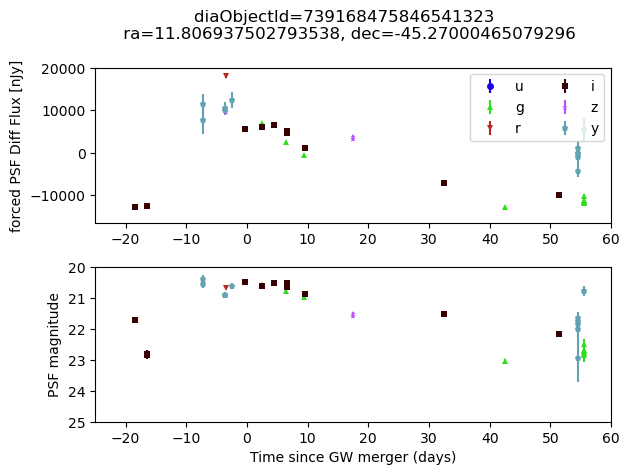

739153082683753247


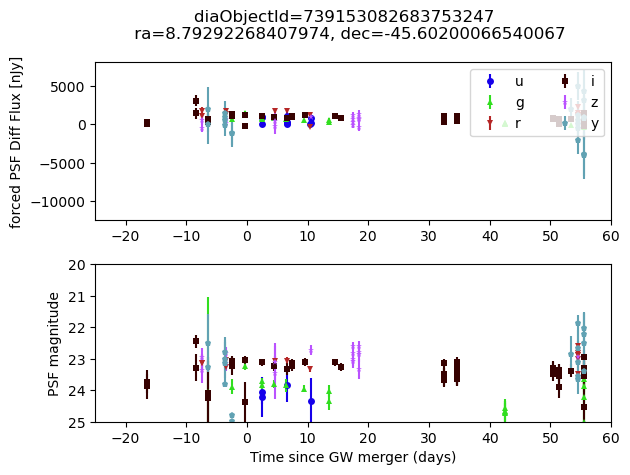

739153082683753200


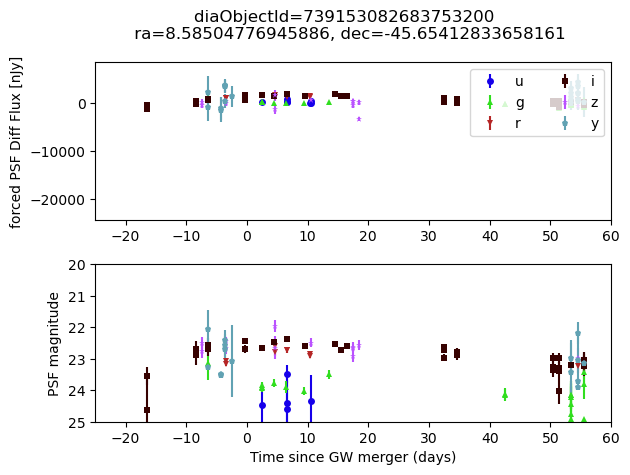

739154388353812577


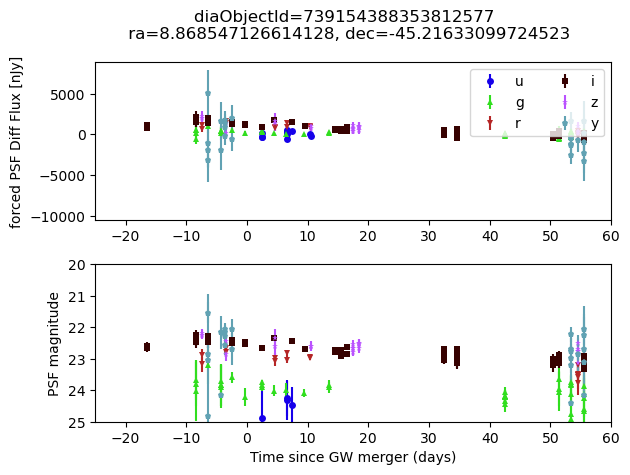

739160641826194338


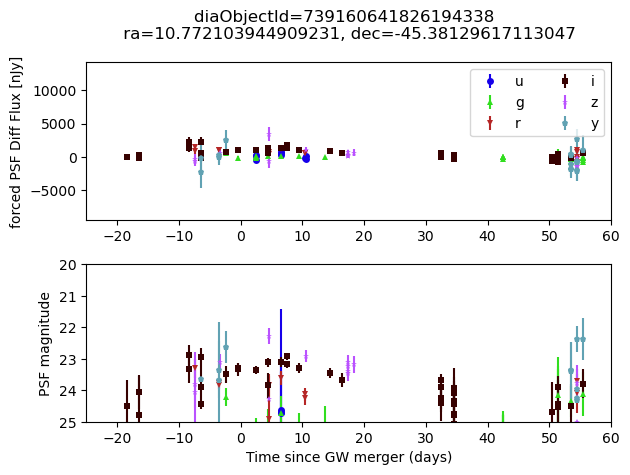

739161260301484127


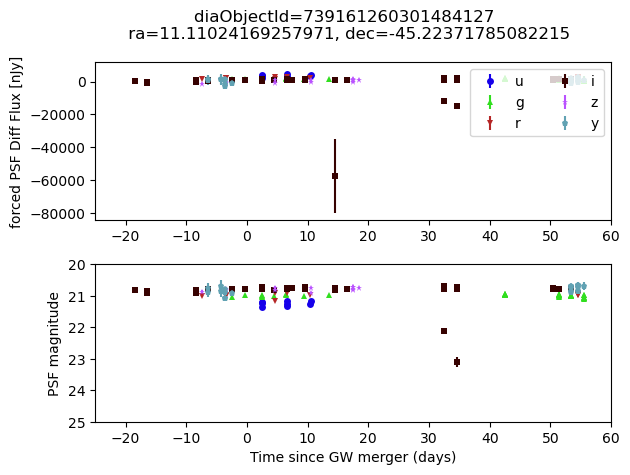

739162703410498030


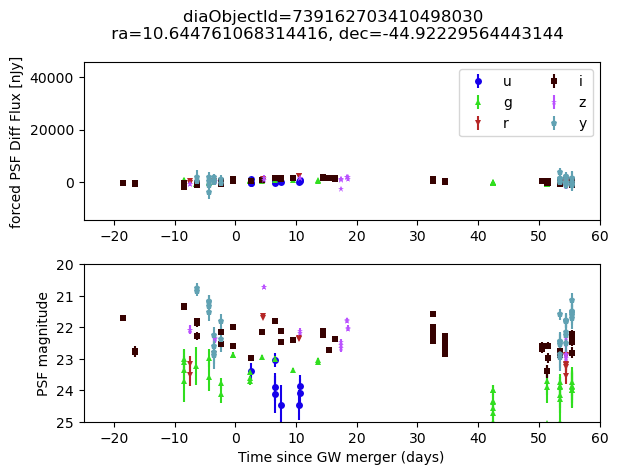

740354024259190921


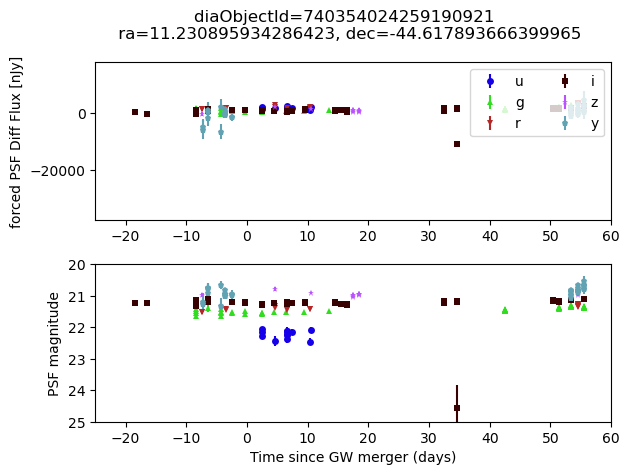

740347358469948908


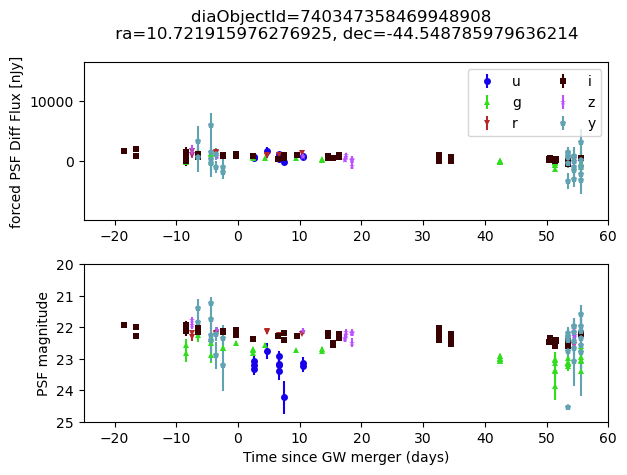

740355261209773127


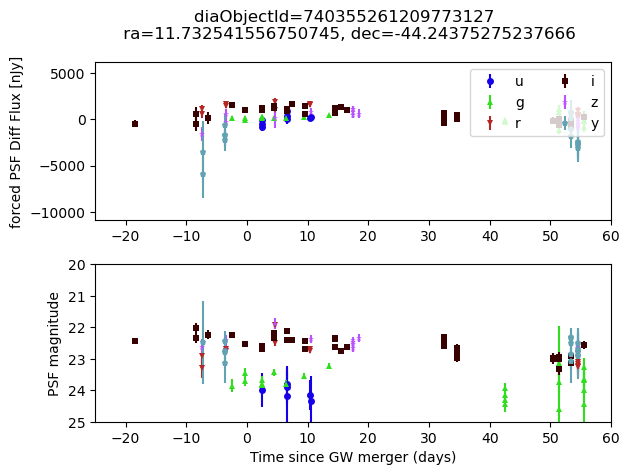

In [26]:
# visualize the diaSource lightcurves
# use the diaObjectForcedSource tables for more accurate photometry

max_plots = 10  # increase to plot more candidates
lc_dir = os.path.join(base_data_path, "DP2_ELAISS1_diaobj_lcs_window")
os.makedirs(lc_dir, exist_ok=True)

for n_plot, dia_obj in enumerate(dia_obj_candidates.itertuples(index=False)):
    if n_plot >= max_plots:
        break
    diaObjectId = dia_obj.diaObjectId
    ra = dia_obj.ra
    dec = dia_obj.dec
    dia_obj_lc = dia_obj.diaObjectForcedSource
    
    gw_mjd = Time(1446995943.36, format='gps').mjd
    fig, (ax1,ax2) = plt.subplots(2, 1)
    print(diaObjectId)
    for f, filt in enumerate(filter_names):
        tx1 = dia_obj_lc["band"] == filt
        ax1.errorbar(dia_obj_lc['midpointMjdTai'][tx1]-gw_mjd, dia_obj_lc['psfDiffFlux'][tx1], yerr=dia_obj_lc["psfDiffFluxErr"][tx1],
                 marker=filter_symbols[filt], ms=5, mew=0, color=filter_colors[filt], label=filt, linestyle='None')
        ax2.errorbar(dia_obj_lc['midpointMjdTai'][tx1]-gw_mjd, dia_obj_lc['psfMag'][tx1], yerr=dia_obj_lc["psfMagErr"][tx1],
                 marker=filter_symbols[filt], ms=5, mew=0, color=filter_colors[filt], label=filt, linestyle='None')

        del tx1
    # ax1.set_xlim([860, 1055])
    # ax2.set_xlim([860, 1055])
    # ax3.set_xlim([860, 1055])
    # ax1.set_ylim([-30000, 62000])
    # ax2.set_ylim([-30000, 62000])
    ax2.set_xlabel('Time since GW merger (days)')
    # ax1.set_ylim([-10000,15
    ax2.set_ylim([25.0, 20.0])
    # ax2.set_xlabel('MJD-60000')
    # ax3.set_xlabel('MJD-60000')
    ax1.set_ylabel('forced PSF Diff Flux [nJy]')
    ax2.set_ylabel('PSF magnitude')
    # ax2.set_ylabel('diaSource PSF Flux [nJy]')
    # ax3.set_ylabel('diaSource PSF Mag')
    ax1.legend(loc='upper right', ncol=2)
    ax1.set_xlim(-25, 60)
    ax2.set_xlim(-25, 60)
    plt.suptitle(f'diaObjectId={diaObjectId} (tier {dia_obj.tier}) \n ra={ra}, dec={dec}', x=0.55)
    plt.tight_layout()
    plt.savefig(os.path.join(lc_dir, f"{diaObjectId}_lc.png"))
    plt.show()

In [ ]:
# filtering on the source properties
query_string = "diaSource.isDipole == 'False' and diaSource.centroid_flag == 'False' and diaSource.apFlux_flag == 'False' and diaSource.psfFlux_flag == 'False' and \
                diaSource.forced_PsfFlux_flag == 'False' and diaSource.shape_flag == 'False' and diaSource.extendedness < 1 and diaSource.reliability > 0.5"

# Additional Exercises

<div class="alert alert-block alert-warning">
<b>Exercise: photometric redshifts</b>

Crossmatch the set of transients recovered from the tutorial above to the native object_photoz catalog (below) or to photometric redshifts from the Legacy Survey using a reasonable crossmatch radius. How many of these transients, if any, have redshifts that are consistent with the distance to the gravitational wave event S251112cm? Explain your reasoning for choosing a crossmatch radius. Can any objects be confidently ruled out with photo-z alone?
</div>

### 2.3. object_photoz

This dataset is provided by the Rubin Commissioning Science Unit for photometric redshift.

<div class="alert alert-block alert-info">
<b>Note:</b> These estimates and their error bars are only very lightly validated. Treat them as provisional and use the results with caution.
</div>

The `object_photoz` table contains four point estimate columns per algorithm, following the format: `{pz_algorithm_name}_z_{point_estimate_type}`, where:
  - `pz_algorithm_name ∈ ['bpz', 'dnf', 'fzboost', 'gpz', 'knn', 'tpz']`
  - `point_estimate_type ∈ ['mode', 'mean', 'median', 'best']` 
    - (where eg, `bpz_z_best` would be bpz's recommended point estimate)

The `object_photoz` table also contains 1σ and 2σ credible interval bound columns per algorithm, following a similar format, `{pz_algorithm_name}_z_{interval_bound}`, where:
  - `pz_algorithm_name ∈ ['bpz', 'dnf', 'fzboost', 'gpz', 'knn', 'tpz']`
  - `interval_bound ∈ ['err68_high', 'err68_low', 'err95_high', 'err95_low']`

In addition, the table provides columns `objectId`, `ra`, and `dec`. 

> **Differences from DP1** include the removal of algorithms `cmnn` and `lephare`, the addition of point estimate `zbest`, and the addition of `ra` and `dec` columns.

As mentioned in Section 1, use of the `object_photoz` table is demonstrated in more detail in the 300-level tutorials.

Load the photo-z table.

In [ ]:
pz_cat = lsdb.open_catalog(base_path / "object_photoz")

Display the results.

In [ ]:
# YOUR CODE BELOW

<div class="alert alert-block alert-warning">
<b>Exercise: the luminosity-timescale phase space</b>

Now, for each object that has an associated photo-z, compute the peak absolute magnitude (luminosity). Then, calculate the characteristic timescale, defined as the amount of time taken to decrease from peak luminosity to half of the peak luminosity (or, approximately, the amount of time taken to decay by one magnitude from the peak magnitude). Plot these objects on the duration-luminosity phase space and compare against the diagram shown in class. How many of these objects fall in the kilonova category? What about the core-collapse or thermonuclear supernova categories?
</div>

In [ ]:
# YOUR CODE BELOW